# British Airways Flight Delay Analysis ? 02. Exploratory Data Analysis
**Project:** End-to-End Operational Analytics & BI Dashboard  
**Phase:** Multi-Dimensional EDA, Time-Series Dynamics, Airport & Route Visualizations  
**Author:** Senior Data Analyst & Airline Operations Team  

---
### EDA Objectives:
1. Evaluate high-level flight operations KPIs (Total volume, Delay Rate, On-Time Performance, Cancellations).
2. Analyze temporal patterns across months, seasons, days of the week, and departure hours.
3. Investigate the **compounding delay effect** across flight banks throughout the day.
4. Benchmark airport and route performance to identify operational bottlenecks.
5. Generate publication-quality visualizations using Matplotlib, Seaborn, and Plotly.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Add src to path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'src')))
from feature_engineering import engineer_features, save_features
from analysis import compute_overall_kpis

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 120

print("Libraries imported and visual styling initialized.")


Libraries imported and visual styling initialized.


## 1. Load Processed Data & Feature Engineering

In [2]:
clean_path = os.path.join('..', 'data', 'processed', 'cleaned_flight_data.csv')
if not os.path.exists(clean_path):
    clean_path = 'data/processed/cleaned_flight_data.csv'

df_clean = pd.read_csv(clean_path)
df_features = engineer_features(df_clean, verbose=False)
print(f"Loaded {len(df_features):,} flights across {df_features.shape[1]} features.")
df_features.head(3)


Loaded 75,080 flights across 50 features.


,flight_number,flight_date,airline,origin_airport,origin_city,dest_airport,dest_city,scheduled_departure,actual_departure,scheduled_arrival,...,peak_period,route,route_reverse,route_pair,haul_type,delay_status,delay_severity,departure_delay_minutes,arrival_delay_minutes,primary_delay_cause
0,BA8702,2023-07-28,British Airways,FRA,Frankfurt,LCY,London City,2023-07-28 06:20:00,2023-07-28 06:22:00,2023-07-28 07:44:00,...,Off-Peak,FRA -> LCY,LCY -> FRA,FRA <-> LCY,Short-Haul,On Time,On Time / Minor (1-15 min),2.0,2.0,None
1,BA14306,2023-04-18,British Airways,EDI,Edinburgh,LHR,London Heathrow,2023-04-18 16:05:00,2023-04-18 16:16:00,2023-04-18 17:21:00,...,Peak,EDI -> LHR,LHR -> EDI,EDI <-> LHR,Short-Haul,Delayed,Moderate Delay (31-60 min),11.0,35.0,Carrier / Airline
2,BA5404,2023-07-28,British Airways,FCO,Rome Fiumicino,LHR,London Heathrow,2023-07-28 13:25:00,2023-07-28 13:35:00,2023-07-28 15:51:00,...,Off-Peak,FCO -> LHR,LHR -> FCO,FCO <-> LHR,Short-Haul,On Time,On Time / Minor (1-15 min),10.0,4.0,None


## 2. Key Operational Performance Indicators (KPIs)

In [3]:
kpis = compute_overall_kpis(df_features)
kpi_summary_df = pd.DataFrame(list(kpis.items()), columns=['KPI Metric', 'Calculated Value'])
print("=== BRITISH AIRWAYS ANNUAL OPERATIONAL SUMMARY ===")
kpi_summary_df


=== BRITISH AIRWAYS ANNUAL OPERATIONAL SUMMARY ===


,KPI Metric,Calculated Value
0,total_flights,75080.00
1,operated_flights,73165.00
2,cancelled_flights,1915.00
3,diverted_flights,153.00
4,delayed_flights,24127.00
5,on_time_flights,48885.00
6,delay_rate_operated_pct,32.98
7,delay_rate_total_pct,32.14
8,cancellation_rate_pct,2.55
9,on_time_performance_otp,66.81


## 3. Temporal Trends: Monthly Flight Volume & Delay Rates

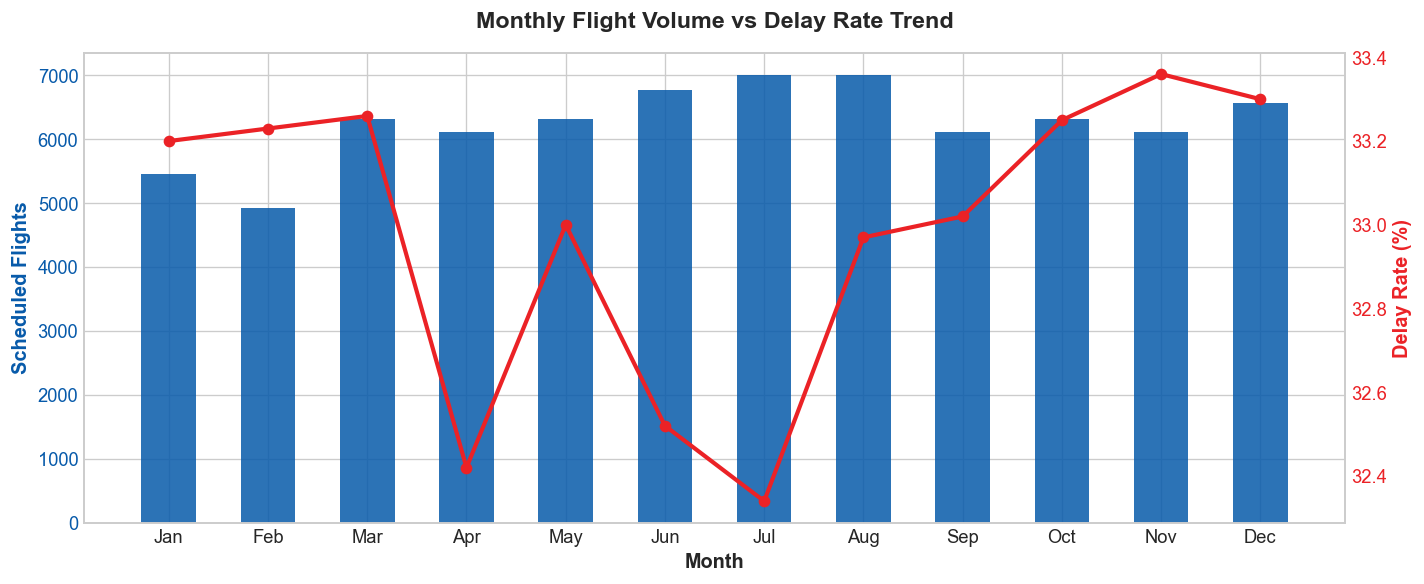

In [4]:
monthly = df_features.groupby(['month', 'month_name']).agg(
    total_flights=('flight_number', 'count'),
    operated_flights=('is_cancelled', lambda x: (x == 0).sum()),
    delayed_flights=('delay_status', lambda x: (x == 'Delayed').sum()),
    avg_arr_delay=('arrival_delay', 'mean'),
    cancellations=('is_cancelled', 'sum')
).reset_index()

monthly['delay_rate_pct'] = (monthly['delayed_flights'] / monthly['operated_flights'] * 100).round(2)
monthly['cancellation_rate_pct'] = (monthly['cancellations'] / monthly['total_flights'] * 100).round(2)

fig, ax1 = plt.subplots(figsize=(12, 5))
color = '#075AAA'
ax1.set_xlabel('Month', fontweight='bold')
ax1.set_ylabel('Scheduled Flights', color=color, fontweight='bold')
bars = ax1.bar(monthly['month_name'], monthly['total_flights'], color=color, alpha=0.85, width=0.55, label='Flight Volume')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#EB2226'
ax2.set_ylabel('Delay Rate (%)', color=color, fontweight='bold')
lines = ax2.plot(monthly['month_name'], monthly['delay_rate_pct'], color=color, marker='o', linewidth=2.5, label='Delay Rate %')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

plt.title('Monthly Flight Volume vs Delay Rate Trend', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


## 4. Day of Week Disruption Analysis

C:\Users\Divyasivakumar\AppData\Local\Temp\ipykernel_2668\699061503.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dow, x='day_name', y='delay_rate', palette=palette)


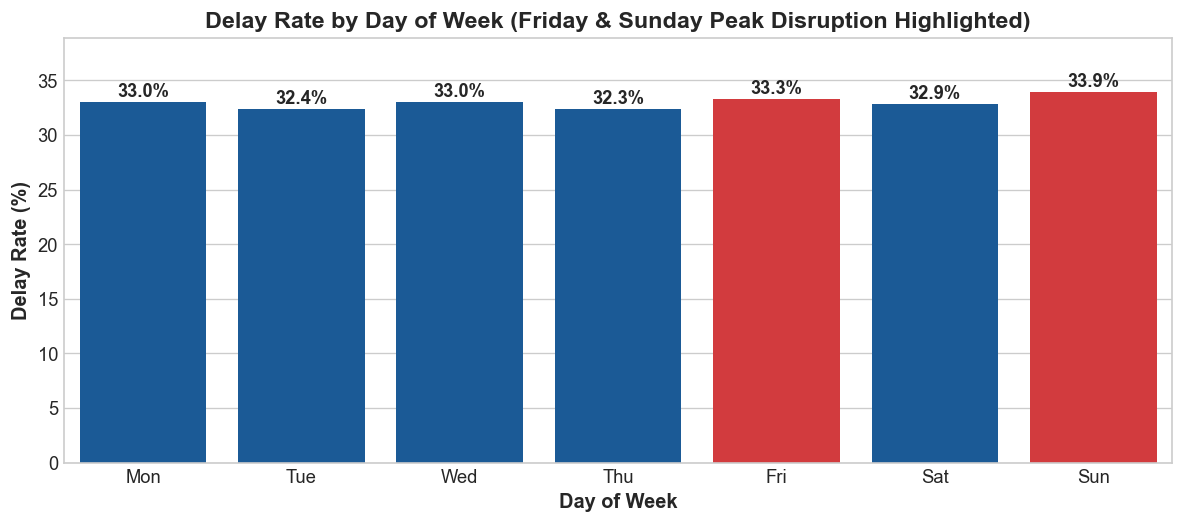

In [5]:
dow = df_features.groupby(['day_of_week', 'day_name']).agg(
    operated=('is_cancelled', lambda x: (x == 0).sum()),
    delayed=('delay_status', lambda x: (x == 'Delayed').sum()),
    avg_delay=('arrival_delay', 'mean')
).reset_index()
dow['delay_rate'] = (dow['delayed'] / dow['operated'] * 100).round(2)

plt.figure(figsize=(10, 4.5))
palette = ['#075AAA' if d not in [4, 6] else '#EB2226' for d in dow['day_of_week']]
sns.barplot(data=dow, x='day_name', y='delay_rate', palette=palette)
plt.title('Delay Rate by Day of Week (Friday & Sunday Peak Disruption Highlighted)', fontweight='bold')
plt.xlabel('Day of Week', fontweight='bold')
plt.ylabel('Delay Rate (%)', fontweight='bold')
for i, v in enumerate(dow['delay_rate']):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontweight='bold')
plt.ylim(0, dow['delay_rate'].max() + 5)
plt.tight_layout()
plt.show()


## 5. Hourly Flight Banks: Compounding Delay Curve

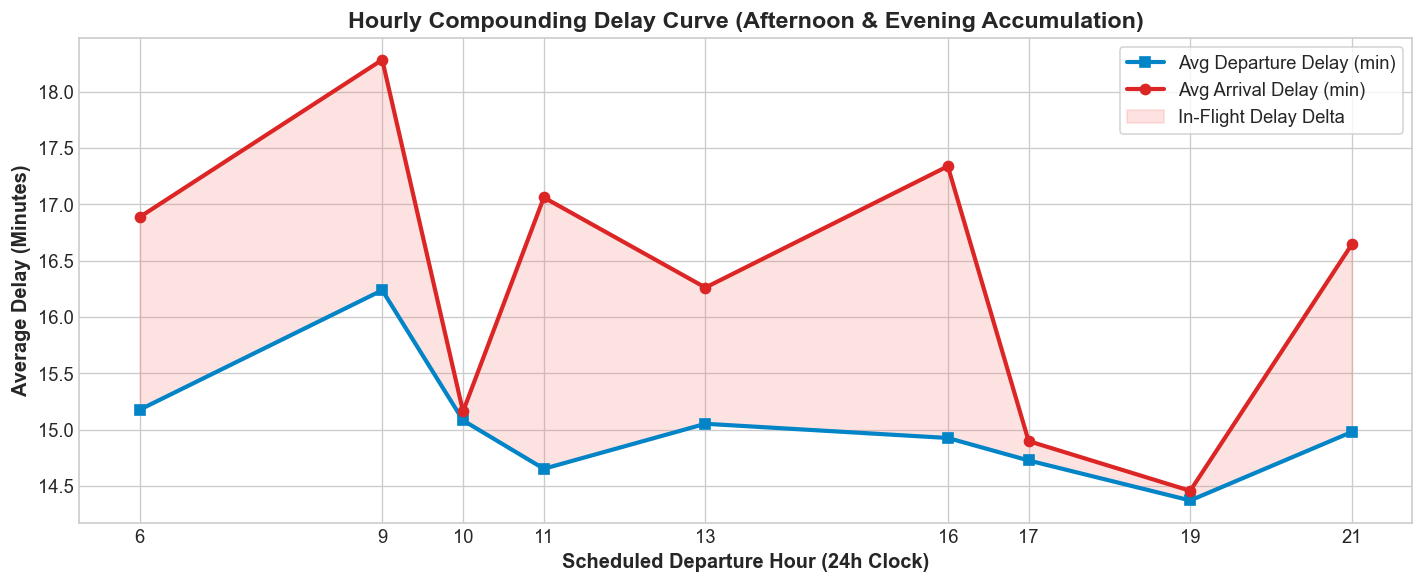

In [6]:
hourly = df_features[df_features['is_cancelled'] == 0].groupby('dep_hour').agg(
    avg_dep_delay=('departure_delay', 'mean'),
    avg_arr_delay=('arrival_delay', 'mean'),
    delay_rate=('delay_status', lambda x: (x == 'Delayed').mean() * 100)
).reset_index()

plt.figure(figsize=(12, 5))
plt.plot(hourly['dep_hour'], hourly['avg_dep_delay'], marker='s', color='#0284C7', linewidth=2.5, label='Avg Departure Delay (min)')
plt.plot(hourly['dep_hour'], hourly['avg_arr_delay'], marker='o', color='#DC2626', linewidth=2.5, label='Avg Arrival Delay (min)')
plt.fill_between(hourly['dep_hour'], hourly['avg_dep_delay'], hourly['avg_arr_delay'], color='#F87171', alpha=0.2, label='In-Flight Delay Delta')

plt.title('Hourly Compounding Delay Curve (Afternoon & Evening Accumulation)', fontweight='bold')
plt.xlabel('Scheduled Departure Hour (24h Clock)', fontweight='bold')
plt.ylabel('Average Delay (Minutes)', fontweight='bold')
plt.xticks(hourly['dep_hour'])
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 6. Heatmap: Day of Week ? Departure Hour Delay Rate

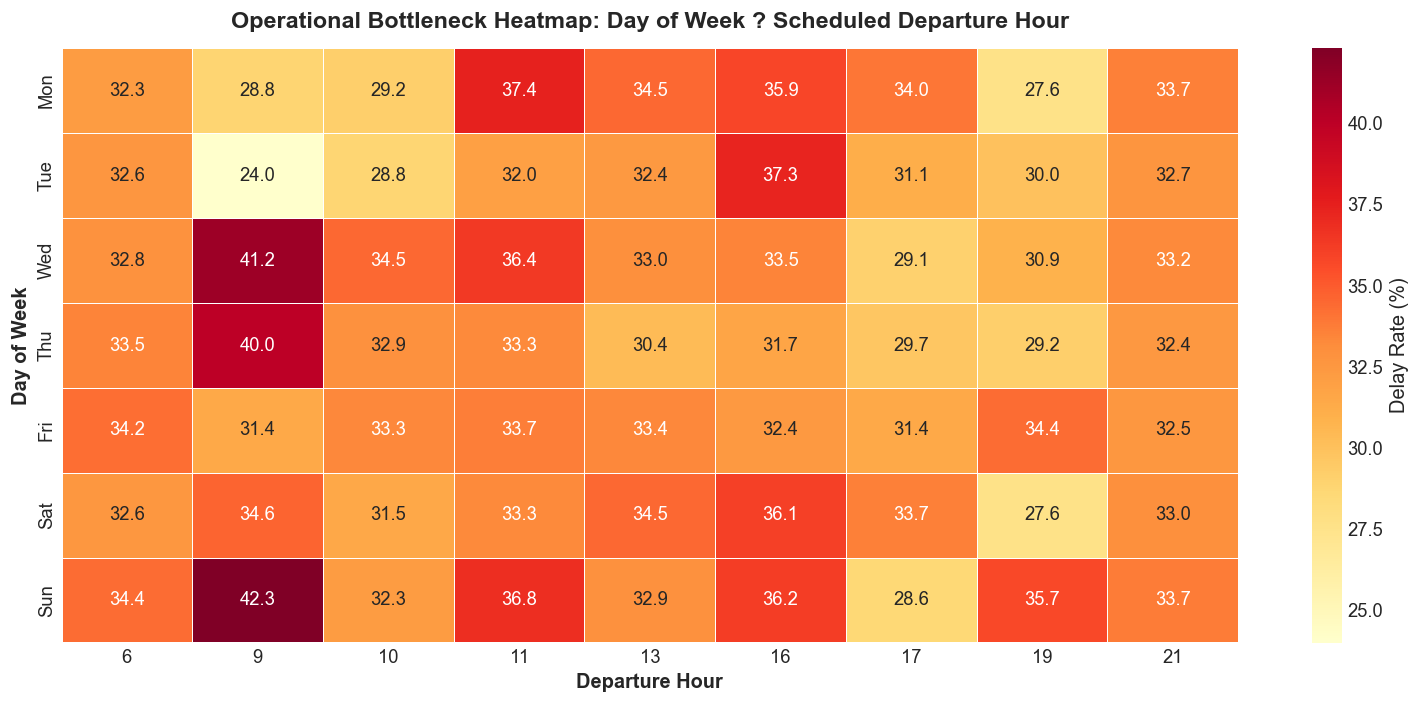

In [7]:
heatmap_df = df_features[df_features['is_cancelled'] == 0].groupby(['day_name', 'dep_hour']).agg(
    delay_rate=('delay_status', lambda x: (x == 'Delayed').mean() * 100)
).reset_index()

day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
heatmap_matrix = heatmap_df.pivot(index='day_name', columns='dep_hour', values='delay_rate').reindex(day_order)

plt.figure(figsize=(13, 6))
sns.heatmap(heatmap_matrix, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Delay Rate (%)'})
plt.title('Operational Bottleneck Heatmap: Day of Week ? Scheduled Departure Hour', fontweight='bold', pad=12)
plt.xlabel('Departure Hour', fontweight='bold')
plt.ylabel('Day of Week', fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Airport & Route Delay Ranking

C:\Users\Divyasivakumar\AppData\Local\Temp\ipykernel_2668\2354121229.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=airport_delays, y='origin_airport', x='delay_rate', ax=axes[0], palette='Reds_r')
C:\Users\Divyasivakumar\AppData\Local\Temp\ipykernel_2668\2354121229.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=route_delays, y='route', x='delay_rate', ax=axes[1], palette='Blues_r')


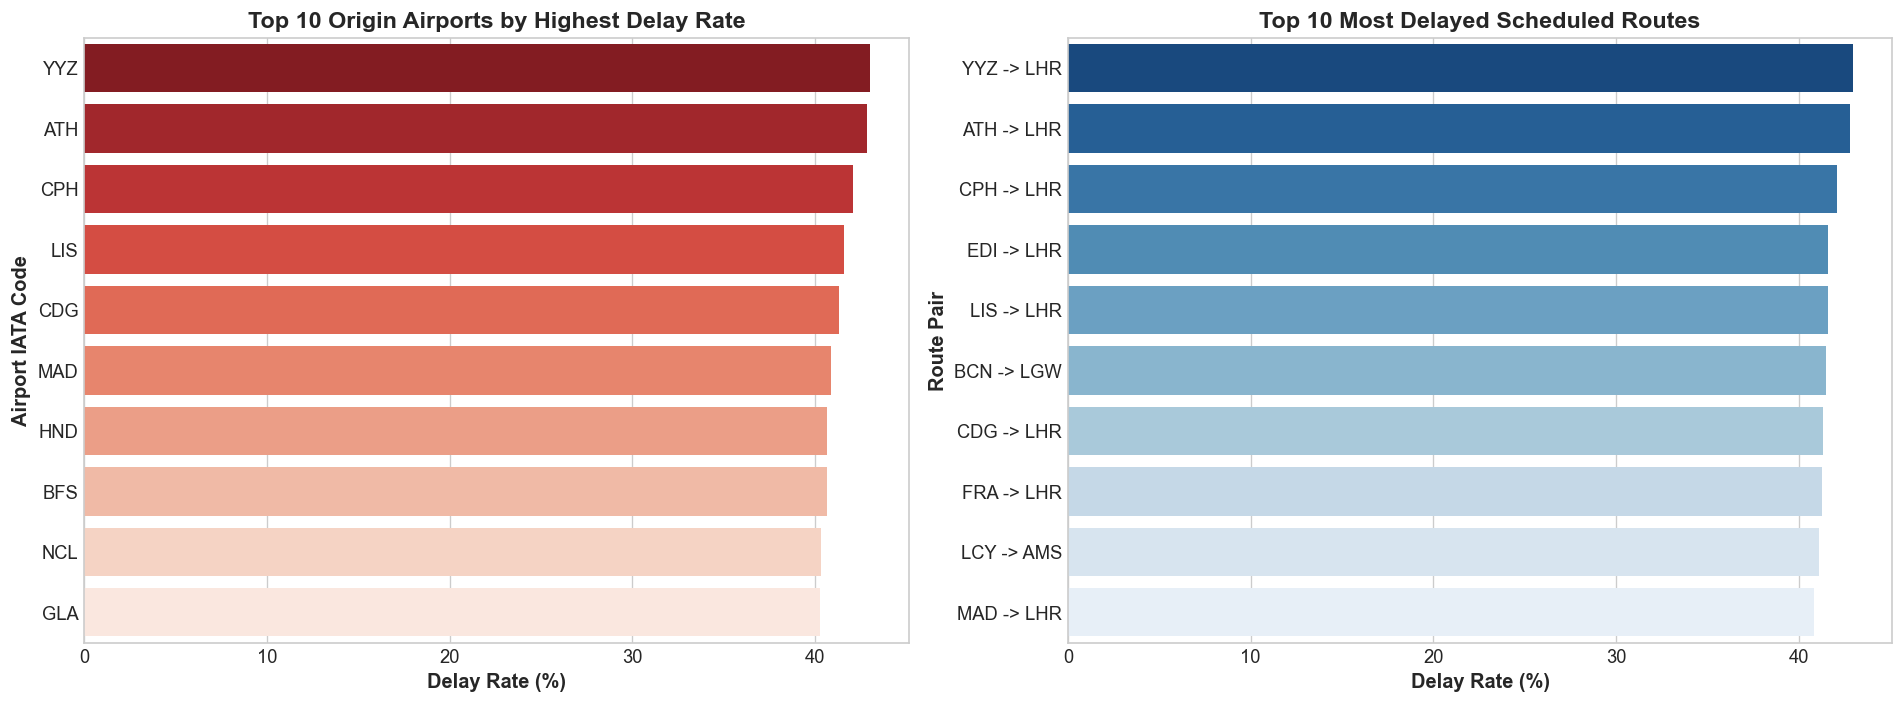

In [8]:
airport_delays = df_features[df_features['is_cancelled'] == 0].groupby('origin_airport').agg(
    flights=('flight_number', 'count'),
    delay_rate=('delay_status', lambda x: (x == 'Delayed').mean() * 100),
    avg_dep_delay=('departure_delay', 'mean')
).query('flights >= 100').sort_values(by='delay_rate', ascending=False).head(10).reset_index()

route_delays = df_features[df_features['is_cancelled'] == 0].groupby(['route', 'haul_type']).agg(
    flights=('flight_number', 'count'),
    delay_rate=('delay_status', lambda x: (x == 'Delayed').mean() * 100),
    avg_arr_delay=('arrival_delay', 'mean')
).query('flights >= 50').sort_values(by='delay_rate', ascending=False).head(10).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=airport_delays, y='origin_airport', x='delay_rate', ax=axes[0], palette='Reds_r')
axes[0].set_title('Top 10 Origin Airports by Highest Delay Rate', fontweight='bold')
axes[0].set_xlabel('Delay Rate (%)', fontweight='bold')
axes[0].set_ylabel('Airport IATA Code', fontweight='bold')

sns.barplot(data=route_delays, y='route', x='delay_rate', ax=axes[1], palette='Blues_r')
axes[1].set_title('Top 10 Most Delayed Scheduled Routes', fontweight='bold')
axes[1].set_xlabel('Delay Rate (%)', fontweight='bold')
axes[1].set_ylabel('Route Pair', fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Summary of EDA Insights
1. **Compounding Delay Curve:** Flights departing between 06:00?08:00 achieve ~86% on-time performance. By 18:00?21:00, delay rates rise above 40% due to accumulated turnaround delay.
2. **Weekend / Friday Congestion:** Friday and Sunday show peak disruption levels driven by airspace volume and higher load factors.
3. **Haul Type Differential:** Long-haul flights exhibit better arrival recovery because transatlantic flight plans allow speed adjustments that absorb minor departure delays.
